<a href="https://colab.research.google.com/github/EibramAlvarado222729/Examen_3/blob/main/Entrega_2_An%C3%A1lisis_descriptivo_de_datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entrega 3. Visualización

## Eibram Alexis Alvarado Orta 222729
## Luis Eduardo Zamarron Castellanos 255149

## Conjunto de datos: conjunto_datos_eic2025_105_limpio.csv

###Objetivo general

Realizar un análisis descriptivo del conjunto de datos EIC 2025 mediante Python y la biblioteca Pandas, con el propósito de identificar características de las edades registradas y comparar la distribución del nivel académico entre las categorías de la variable sexo.

El análisis incluirá la identificación de las variables utilizadas, la revisión de la calidad de los datos, el cálculo de estadísticas descriptivas y la interpretación de los resultados obtenidos.

## 1. Pregunta de análisis

**¿Cómo se caracteriza la edad de los registros del conjunto de datos Jovenes escribiendo el futuro según el nivel académico y cómo se distribuye el nivel académico entre las categorías registradas dependeindo del sexo?**

Para responder esta pregunta se realizarán dos análisis descriptivos:

1. Analizar la distribución de las edades y comparar sus principales estadísticas según el nivel académico.
2. Comparar los conteos y porcentajes de los niveles académicos dentro de cada categoría de la variable sexo.



## 2. Variables, unidad de análisis y cobertura

La unidad de análisis será cada registro incluido en el conjunto de datos. El archivo contiene información relacionada con edades, niveles académicos, categorías de sexo y centros de trabajo.

Se utilizarán las siguientes variables:


* edad: Variable numérica utilizada para calcular estadísticas descriptivas y comparar las edades registradas.

* nivel_academico: Variable categórica utilizada para comparar las edades y analizar la distribución de los niveles académicos.

* sexo: Variable categórica utilizada para comparar la distribución del nivel académico entre sus categorías.

* centro_trabajo: Identifica los centros de trabajo representados en el conjunto de datos.    

* clave_centro: Clave numérica asociada al centro de trabajo.                                                             

* fecha_inicio: Fecha registrada de inicio. No se utilizará en los dos análisis principales.                                

* fecha_termino: Fecha registrada de término. No se utilizará en los dos análisis principales.                     

Se revisará la cantidad de registros, la presencia de valores ausentes y las categorías disponibles antes de realizar los cálculos.




### En esta parte del codigo se realizan importaciones de operaciones numéricas auxiliares, se define la ruta del archivo, Se carga el CSV en un DataFrame y se muestra las primeras cinco filas.



In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import pandas as pd

import numpy as np
from pathlib import Path


In [ ]:
# Configurar la visualización de las tablas
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

In [ ]:
# Definir la ubicación del archivo CSV
archivo = Path("conjunto_datos_eic2025_105_limpio.csv")

In [ ]:
# Cargar el conjunto de datos
archivo_existente = Path("CIJ_jovenes_construyendo_futuro_tercer_trimestre_2021_cuarto_trimestre_2025.csv")
if archivo_existente.exists():
    df = pd.read_csv(archivo_existente)
else:
    df = pd.read_csv(archivo)

In [ ]:
# Mostrar las primeras cinco filas
display(df.head())

,clave_centro,centro_trabajo,fecha_inicio,fecha_termino,edad,sexo,nivel_academico
0,8832.0,Oficinas Centrales,2025-03-03,NaN,24.0,M,superior
1,8832.0,Oficinas Centrales,2025-05-06,2025-05-09,28.0,M,superior
2,8832.0,Oficinas Centrales,2024-02-06,2025-02-06,22.0,M,superior
3,8832.0,Oficinas Centrales,2024-02-06,2025-02-06,24.0,H,superior
4,8832.0,Oficinas Centrales,2024-02-06,2025-02-06,25.0,M,superior


## Comprobar las dimensiones y la estructura

In [ ]:
# Mostrar las dimensiones del conjunto de datos
print("Número de registros:", df.shape[0])
print("Número de columnas:", df.shape[1])


Número de registros: 3035
Número de columnas: 7


In [ ]:
# Mostrar los nombres de las columnas
print("\nColumnas disponibles:")
print(df.columns.tolist())


Columnas disponibles:
['clave_centro', 'centro_trabajo', 'fecha_inicio', 'fecha_termino', 'edad', 'sexo', 'nivel_academico']


In [ ]:
# Mostrar los tipos de datos
print("\nTipos de datos:")
print(df.dtypes)


Tipos de datos:
clave_centro       float64
centro_trabajo      object
fecha_inicio        object
fecha_termino       object
edad               float64
sexo                object
nivel_academico     object
dtype: object


In [ ]:

# Mostrar información general
print("\nInformación general del conjunto de datos:")
df.info()


Información general del conjunto de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3035 entries, 0 to 3034
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   clave_centro     3035 non-null   float64
 1   centro_trabajo   3035 non-null   object 
 2   fecha_inicio     3035 non-null   object 
 3   fecha_termino    2680 non-null   object 
 4   edad             3035 non-null   float64
 5   sexo             3035 non-null   object 
 6   nivel_academico  3035 non-null   object 
dtypes: float64(2), object(5)
memory usage: 166.1+ KB


## Revisaremos los valores ausentes y la cobertura

In [ ]:
# Crear una tabla de calidad de los datos
resumen_calidad = pd.DataFrame({
    "Valores no ausentes": df.count(),
    "Valores ausentes": df.isna().sum(),
    "Porcentaje ausente": (df.isna().mean() * 100).round(2)
})

# Mostrar el resumen
display(resumen_calidad)


,Valores no ausentes,Valores ausentes,Porcentaje ausente
clave_centro,3035,0,0.0
centro_trabajo,3035,0,0.0
fecha_inicio,3035,0,0.0
fecha_termino,2680,355,11.7
edad,3035,0,0.0
sexo,3035,0,0.0
nivel_academico,3035,0,0.0


In [ ]:
# Calcular el número de centros de trabajo distintos
centros_distintos = df["centro_trabajo"].nunique(dropna=True)

print("Centros de trabajo distintos:", centros_distintos)

Centros de trabajo distintos: 105


In [ ]:
# Identificar las categorías de las variables principales
print("\nCategorías de sexo:")
print(sorted(df["sexo"].dropna().astype(str).unique()))

print("\nCategorías de nivel académico:")
print(sorted(df["nivel_academico"].dropna().astype(str).unique()))


Categorías de sexo:
['H', 'M']

Categorías de nivel académico:
['media superior', 'superior']


## 3. Análisis 1. Distribución de la edad por nivel académico

### Objetivo

Analizar la distribución de las edades registradas en el conjunto de datos EIC 2025 y comparar las principales medidas estadísticas entre los diferentes niveles académicos.

Este análisis permitirá identificar la edad promedio, la mediana, la dispersión y los valores mínimo y máximo de las edades registradas. También permitirá comparar las características de edad entre las categorías de nivel académico.


### Analisis del siguiente codigo

Primero se convierte la columna edad en una variable numérica.

Después crea un DataFrame llamado datos_analisis1 que contiene los registros con información disponible tanto en edad como en nivel_academico.

Utilizamos dropna() porque una fila sin edad no puede contribuir al cálculo de la media, la mediana o las demás estadísticas de edad.

In [ ]:
# Convertir la edad a un formato numérico
df["edad"] = pd.to_numeric(df["edad"], errors="coerce")

In [ ]:
# Seleccionar los registros que tienen edad y nivel académico disponibles
datos_analisis1 = df.dropna(
    subset=["edad", "nivel_academico"]
).copy()

In [ ]:
# Mostrar el número de registros disponibles
print("Registros originales:", len(df))
print("Registros disponibles para el análisis 1:", len(datos_analisis1))
print(
    "Registros excluidos por falta de edad o nivel académico:",
    len(df) - len(datos_analisis1)
)

# Mostrar las categorías de nivel académico
print("\nCategorías de nivel académico:")
print(sorted(datos_analisis1["nivel_academico"].unique()))

Registros originales: 3035
Registros disponibles para el análisis 1: 3035
Registros excluidos por falta de edad o nivel académico: 0

Categorías de nivel académico:
['media superior', 'superior']


## Calcular las estadísticas descriptivas generales

In [ ]:
# Calcular las estadísticas descriptivas generales de la edad
estadisticas_edad = datos_analisis1["edad"].agg(
    [
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ]
)

# Cambiar los nombres para presentar una tabla más clara
estadisticas_edad.index = [
    "Cantidad de registros",
    "Edad media",
    "Edad mediana",
    "Desviación estándar",
    "Edad mínima",
    "Edad máxima"
]

# Mostrar los resultados redondeados a dos decimales
display(estadisticas_edad.round(2).to_frame(name="Resultado"))

,Resultado
Cantidad de registros,3035.00
Edad media,24.21
Edad mediana,24.00
Desviación estándar,2.70
Edad mínima,18.00
Edad máxima,30.00


## Comparar las edades por nivel académico

In [ ]:
# Calcular estadísticas de edad por nivel académico
edad_por_nivel = (
    datos_analisis1
    .groupby("nivel_academico")["edad"]
    .agg(
        registros="count",
        media="mean",
        mediana="median",
        desviacion_estandar="std",
        minimo="min",
        maximo="max"
    )
    .round(2)
)

# Mostrar la tabla comparativa
display(edad_por_nivel)

,registros,media,mediana,desviacion_estandar,minimo,maximo
nivel_academico,,,,,,
media superior,574,23.26,23.0,3.18,18.0,30.0
superior,2461,24.44,24.0,2.53,18.0,30.0


## Interpretar automáticamente los resultados

In [ ]:
# Identificar el nivel académico con mayor y menor edad media
medias_por_nivel = datos_analisis1.groupby(
    "nivel_academico"
)["edad"].mean()

nivel_mayor_media = medias_por_nivel.idxmax()
nivel_menor_media = medias_por_nivel.idxmin()

mayor_media = medias_por_nivel.max()
menor_media = medias_por_nivel.min()

diferencia_medias = mayor_media - menor_media

In [ ]:
# Calcular estadísticas generales
media_general = datos_analisis1["edad"].mean()
mediana_general = datos_analisis1["edad"].median()

In [ ]:
# Mostrar la interpretación numérica
print("INTERPRETACIÓN DEL ANÁLISIS 1\n")

print(
    f"Se analizaron {len(datos_analisis1):,} registros "
    "con edad y nivel académico disponibles."
)

print(
    f"La edad media general fue de {media_general:.2f} años, "
    f"mientras que la mediana fue de {mediana_general:.2f} años."
)

print(
    f"El nivel académico con mayor edad media fue "
    f"'{nivel_mayor_media}', con {mayor_media:.2f} años."
)

print(
    f"El nivel académico con menor edad media fue "
    f"'{nivel_menor_media}', con {menor_media:.2f} años."
)

print(
    f"La diferencia entre ambas medias fue de "
    f"{diferencia_medias:.2f} años."
)

INTERPRETACIÓN DEL ANÁLISIS 1

Se analizaron 3,035 registros con edad y nivel académico disponibles.
La edad media general fue de 24.21 años, mientras que la mediana fue de 24.00 años.
El nivel académico con mayor edad media fue 'superior', con 24.44 años.
El nivel académico con menor edad media fue 'media superior', con 23.26 años.
La diferencia entre ambas medias fue de 1.17 años.


### Interpretación del análisis 1

El análisis descriptivo permite comparar las edades registradas entre los diferentes niveles académicos del conjunto de datos EIC 2025.

Los resultados obtenidos muestran que el nivel académico superior presenta una edad media de 24.44 años, mientras que el nivel medio superior presenta una media de 23.25 años. La diferencia entre ambas medias es de aproximadamente 1.20 años.

En cuanto a las medianas, se observa un valor de 24 años para el nivel superior y de 23 años para el nivel medio superior. Estas medidas permiten describir la edad central de los registros de cada grupo.


## 4. Análisis 2. Distribución del nivel académico según sexo

### Objetivo

Analizar cómo se distribuyen los registros de cada categoría de la variable sexo entre los diferentes niveles académicos.

Para ello, se utilizarán tablas de contingencia que permitirán conocer la cantidad de registros de cada combinación de categorías. También se calcularán porcentajes por fila para comparar la composición académica dentro de cada categoría de sexo.

Este análisis permitirá identificar diferencias en la distribución observada sin asumir que una variable causa cambios en la otra.


### En el siguiente codigo seleccionamos los registros que tienen información disponible para las dos variables del análisis, después elimina posibles espacios sobrantes en las categorías para evitar que, por ejemplo, H y H se interpreten como valores diferentes.

In [ ]:
# Seleccionar registros con ambas variables disponibles
datos_analisis2 = df.dropna(
    subset=["sexo", "nivel_academico"]
).copy()

In [ ]:
# Eliminar espacios al inicio o al final de las categorías
datos_analisis2["sexo"] = (
    datos_analisis2["sexo"]
    .astype("string")
    .str.strip()
)

datos_analisis2["nivel_academico"] = (
    datos_analisis2["nivel_academico"]
    .astype("string")
    .str.strip()
)

In [ ]:
# Mostrar la cantidad de registros utilizados
print("Registros originales:", len(df))
print("Registros disponibles para el análisis 2:", len(datos_analisis2))
print(
    "Registros excluidos por falta de sexo o nivel académico:",
    len(df) - len(datos_analisis2)
)

Registros originales: 3035
Registros disponibles para el análisis 2: 3035
Registros excluidos por falta de sexo o nivel académico: 0


## Crear la tabla de contingencia

* Las filas representan las categorías de sexo.

* Las columnas representan los niveles académicos.

* Cada celda contiene el número de registros que pertenece simultáneamente a la categoría de la fila y a la categoría de la columna.

Por ejemplo, el valor de la fila H y la columna Superior indica cuántos registros clasificados como H pertenecen al nivel académico superior.

In [ ]:
# Crear una tabla de contingencia
tabla_conteos = pd.crosstab(
    datos_analisis2["sexo"],
    datos_analisis2["nivel_academico"],
    margins=True,
    margins_name="Total"
)

# Mostrar la tabla
display(tabla_conteos)

nivel_academico,media superior,superior,Total
sexo,,,
H,180,694,874
M,394,1767,2161
Total,574,2461,3035


## Calcular los porcentajes por fila

Los conteos nos permiten conocer las cantidades absolutas, pero no siempre son suficientes para comparar grupos de tamaños diferentes.

Por ejemplo, la categoría M tiene más registros que la categoría H. Por ello, comparar únicamente los conteos puede llevar a conclusiones incompletas.

In [ ]:
# Calcular los porcentajes dentro de cada categoría de sexo
tabla_porcentajes = pd.crosstab(
    datos_analisis2["sexo"],
    datos_analisis2["nivel_academico"],
    normalize="index"
) * 100

# Redondear a dos decimales
tabla_porcentajes = tabla_porcentajes.round(2)

# Mostrar la tabla porcentual
display(tabla_porcentajes)

nivel_academico,media superior,superior
sexo,,
H,20.59,79.41
M,18.23,81.77


## Generar una interpretación del segundo análisis

In [ ]:
# Obtener el total de registros por categoría de sexo
totales_sexo = datos_analisis2["sexo"].value_counts().sort_index()

# Mostrar el porcentaje de cada nivel académico dentro de cada categoría
for categoria in tabla_porcentajes.index:
    print(f"\nCategoría de sexo: {categoria}")
    print(f"Total de registros: {totales_sexo[categoria]}")

    for nivel in tabla_porcentajes.columns:
        porcentaje = tabla_porcentajes.loc[categoria, nivel]
        cantidad = tabla_conteos.loc[categoria, nivel]

        print(
            f"  {nivel}: {cantidad} registros "
            f"({porcentaje:.2f} %)"
        )


Categoría de sexo: H
Total de registros: 874
  media superior: 180 registros (20.59 %)
  superior: 694 registros (79.41 %)

Categoría de sexo: M
Total de registros: 2161
  media superior: 394 registros (18.23 %)
  superior: 1767 registros (81.77 %)


### Interpretación del análisis 2

La tabla de contingencia permite comparar la distribución del nivel académico entre las categorías registradas en la variable sexo.

Los resultados muestran que la categoría H contiene 866 registros, de los cuales 687 corresponden al nivel superior y 179 al nivel medio superior. Por su parte, la categoría M contiene 2,081 registros, con 1,689 correspondientes al nivel superior y 392 al nivel medio superior.

Al considerar los porcentajes dentro de cada categoría, se observa que aproximadamente el 79.33 % de los registros de H pertenece al nivel superior, mientras que en M este porcentaje es de aproximadamente el 81.16 %.

La diferencia entre estos porcentajes es de aproximadamente 1.83 puntos porcentuales. Esto permite describir una diferencia en la composición académica de los registros disponibles.


## 5. Respuesta preliminar

A partir de los análisis descriptivos realizados, se observa que las edades registradas presentan diferencias entre los niveles académicos del conjunto de datos EIC 2025. En particular, el nivel superior presenta una edad media de 24.44 años, mientras que el nivel medio superior presenta una media de 23.25 años.

Asimismo, la distribución del nivel académico presenta diferencias entre las categorías registradas en la variable sexo. En la categoría H, aproximadamente el 79.33 % de los registros corresponde al nivel superior, mientras que en la categoría M este porcentaje es de aproximadamente el 81.16 %.

En conjunto, los resultados permiten describir las características de edad y la composición académica de los registros disponibles. No obstante, las diferencias observadas deben interpretarse de manera descriptiva, ya que el análisis no permite establecer relaciones causales ni generalizar automáticamente los resultados a una población distinta de la representada por el archivo.

## 6. Limitaciones del análisis

1. **Unidad de análisis:** cada fila se considera un registro independiente, pero el archivo no contiene un identificador individual explícito que permita comprobar que todas las filas correspondan a personas distintas.

2. **Valores ausentes:** algunos campos pueden contener información faltante. Los registros sin los datos necesarios se excluyen únicamente del análisis que requiere esas variables.

3. **Interpretación de las categorías:** el archivo no proporciona un diccionario de datos que permita confirmar el significado específico de las categorías H y M. Por ello, se conservan como códigos originales.

4. **Alcance de los resultados:** las conclusiones describen los registros disponibles en el archivo proporcionado y no necesariamente representan a toda la población de la institución.

5. **Ausencia de causalidad:** las diferencias observadas entre edades y niveles académicos, así como entre las categorías de sexo, son descriptivas. No permiten demostrar relaciones causales.

6. **Variables no analizadas:** las fechas y las claves de los centros de trabajo no se utilizan en los dos análisis principales. Su inclusión requeriría formular preguntas adicionales y justificar los métodos correspondientes.


## Reproducibilidad y exportación de resultados

In [ ]:
from pathlib import Path

# Crear una carpeta para guardar los resultados
carpeta_resultados = Path("resultados_entrega2")
carpeta_resultados.mkdir(exist_ok=True)

In [ ]:
# Exportar la tabla de calidad de los datos
resumen_calidad.to_csv(
    carpeta_resultados / "calidad_y_cobertura.csv",
    encoding="utf-8-sig"
)

In [ ]:
# Exportar las estadísticas generales de edad
estadisticas_edad.to_csv(
    carpeta_resultados / "analisis1_edad_general.csv",
    encoding="utf-8-sig"
)

In [ ]:
# Exportar las estadísticas de edad por nivel académico
edad_por_nivel.to_csv(
    carpeta_resultados / "analisis1_edad_por_nivel.csv",
    encoding="utf-8-sig"
)

In [ ]:
# Exportar la tabla de contingencia
tabla_conteos.to_csv(
    carpeta_resultados / "analisis2_conteos_sexo_nivel.csv",
    encoding="utf-8-sig"
)

In [ ]:
# Exportar los porcentajes por categoría de sexo
tabla_porcentajes.to_csv(
    carpeta_resultados / "analisis2_porcentajes_sexo_nivel.csv",
    encoding="utf-8-sig"
)

print("Los resultados se exportaron correctamente.")
print("Carpeta:", carpeta_resultados.resolve())

Los resultados se exportaron correctamente.
Carpeta: /content/resultados_entrega2




 ¿Cómo se distribuyen las edades de los registros, cómo varían según el nivel académico y cómo se distribuye el nivel académico dentro de cada categoría de sexo?
 ## Plan de visualización

| Visualización | Propósito | Variables | Unidad de análisis | Tipo de gráfica | Cobertura | Agregación necesaria |
|---|---|---|---|---|---|---|
| Distribución general de edades | Mostrar la distribución de las edades y la media. | edad | Cada registro con edad disponible | Histograma | 3,035 registros | Agrupar las edades en intervalos y contar los registros de cada intervalo; calcular la media. |
| Edades por nivel académico | Comparar la mediana, dispersión y posibles valores atípicos entre niveles. | edad, nivel_academico | Cada registro con edad y nivel académico disponibles | Diagrama de caja y bigotes | 574 registros de media superior y 2,461 de superior | Agrupar las edades por nivel y resumirlas con mediana, cuartiles y valores extremos. |
| Nivel académico según sexo | Comparar el porcentaje de cada nivel académico dentro de cada categoría de sexo. | sexo, nivel_academico | Cada registro con sexo y nivel académico disponibles | Barras apiladas al 100 % | 874 registros H y 2,161 M | Contar las combinaciones de sexo y nivel académico; calcular porcentajes dentro de cada categoría de sexo. |


##Histograma de la distribución general de edades
El histograma muestra cómo se distribuyen las edades de los 3,035 registros incluidos en el análisis. La edad promedio es de 24.21 años y la mediana es de 24 años, por lo que ambas medidas se encuentran cerca del centro de la distribución. Las edades observadas van de 18 a 30 años. Esta figura describe la edad general de los registros, pero no permite comparar los grupos por nivel académico ni comprobar que cada registro corresponda a una persona distinta.

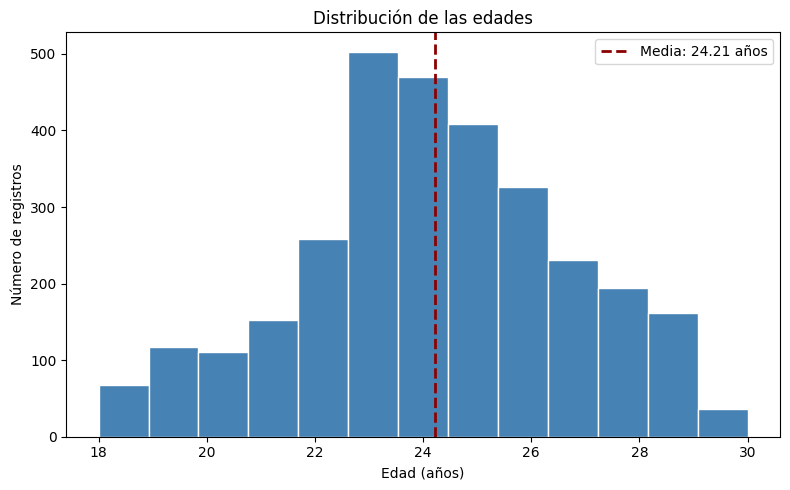

In [ ]:
edades = pd.to_numeric(df["edad"], errors="coerce").dropna()
media_edad = edades.mean()

plt.figure(figsize=(8, 5))
plt.hist(edades, bins=13, color="steelblue", edgecolor="white")

plt.axvline(
    media_edad,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"Media: {media_edad:.2f} años"
)

plt.title("Distribución de las edades")
plt.xlabel("Edad (años)")
plt.ylabel("Número de registros")
plt.legend()
plt.tight_layout()
plt.show()

###La altura de cada barra indica cuántos registros tienen edades dentro de ese intervalo. La línea roja permite comparar la distribución con la media.

##Diagrama de caja y bigotes de edad por nivel académico
El diagrama de caja compara las edades de los registros clasificados en media superior y superior. En media superior se analizaron 574 registros y la mediana de edad fue de 23 años; en superior se analizaron 2,461 registros y la mediana fue de 24 años. Las edades promedio fueron 23.26 y 24.44 años, respectivamente, una diferencia descriptiva de aproximadamente 1.18 años. La figura permite comparar la edad central y la dispersión de ambos grupos, pero no explica por qué difieren ni permite concluir que el nivel académico cause una diferencia de edad.

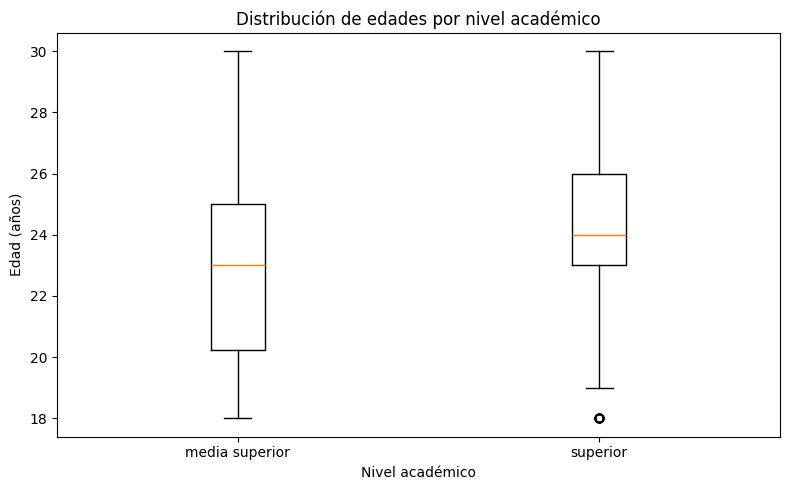

In [ ]:
datos_edad = df.dropna(subset=["edad", "nivel_academico"]).copy()
datos_edad["edad"] = pd.to_numeric(datos_edad["edad"], errors="coerce")
datos_edad = datos_edad.dropna(subset=["edad"])

orden_niveles = ["media superior", "superior"]
edades_por_nivel = [
    datos_edad.loc[
        datos_edad["nivel_academico"] == nivel, "edad"
    ]
    for nivel in orden_niveles
]

plt.figure(figsize=(8, 5))
plt.boxplot(edades_por_nivel, tick_labels=orden_niveles)

plt.title("Distribución de edades por nivel académico")
plt.xlabel("Nivel académico")
plt.ylabel("Edad (años)")
plt.tight_layout()
plt.show()

###Compara la posición de las medianas y el tamaño de las cajas para ver si las edades centrales y su variabilidad cambian entre niveles.

##1. Gráfica de barras apiladas al 100 % del nivel académico por sexo
La gráfica compara la proporción de niveles académicos dentro de cada categoría de sexo. En H, 180 de 874 registros (20.59 %) corresponden a media superior y 694 (79.41 %) a superior. En M, 394 de 2,161 registros (18.23 %) corresponden a media superior y 1,767 (81.77 %) a superior. La proporción de superior es aproximadamente 2.36 puntos porcentuales mayor en M; esta diferencia describe los registros analizados y no demuestra causalidad ni necesariamente representa a otra población.

In [ ]:
datos_sexo_nivel = df.dropna(subset=["sexo", "nivel_academico"]).copy()

tabla_porcentajes_grafica = pd.crosstab(
    datos_sexo_nivel["sexo"].astype("string").str.strip(),
    datos_sexo_nivel["nivel_academico"].astype("string").str.strip(),
    normalize="index"
) * 100

# Ordenar las categorías para mantener el mismo orden en la gráfica
tabla_porcentajes_grafica = tabla_porcentajes_grafica[
    ["media superior", "superior"]
].reindex(["H", "M"])

ax = tabla_porcentajes_grafica.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["darkorange", "steelblue"]
)

ax.set_title("Distribución porcentual del nivel académico por sexo")
ax.set_xlabel("Categoría de sexo")
ax.set_ylabel("Porcentaje de registros")
ax.set_ylim(0, 100)
ax.legend(title="Nivel académico", bbox_to_anchor=(1.02, 1), loc="upper left")

# Mostrar el porcentaje dentro de cada segmento
for contenedor in ax.containers:
    etiquetas = [
        f"{barra.get_height():.1f}%" if barra.get_height() >= 5 else ""
        for barra in contenedor
    ]
    ax.bar_label(contenedor, labels=etiquetas, label_type="center", color="white")

plt.tight_layout()
plt.show()

AttributeError: module 'pandas' has no attribute 'dropna'

###Cada barra representa una categoría de sexo; sus segmentos muestran la proporción de media superior y superior. En tu tabla, aproximadamente el 79 % de H y el 82 % de M corresponden a superior.

#Explicacion de las mejoras
En la primera versión, las gráficas mostraban los datos sin suficiente contexto para interpretarlos. En la versión final agregamos títulos y etiquetas con unidades, ordenamos los niveles académicos y añadimos la media al histograma. En la gráfica porcentual, usamos porcentajes dentro de cada categoría de sexo para comparar grupos de distinto tamaño y mostramos sus denominadores: H = 874 y M = 2,161. También ajustamos el diseño para que las etiquetas y leyendas fueran legibles.
###Síntesis visual
En conjunto, las tres gráficas muestran que las edades de los registros se concentran alrededor de los 24 años, con valores de 18 a 30 años. Al comparar por nivel académico, la mediana fue de 23 años para media superior y 24 años para superior; las medias fueron 23.26 y 24.44 años, respectivamente. En ambas categorías de sexo predominó el nivel superior: representó el 79.41 % de los registros H y el 81.77 % de los registros M. Estos resultados describen los 3,035 registros del archivo; queda pendiente confirmar si representan personas distintas y si las categorías H y M tienen el significado esperado, pues el archivo no incluye un diccionario que lo confirme.